# Анализ временного ряда продаж Online Retail

In [1]:
%matplotlib inline

from pathlib import Path

import pandas as pd
from IPython.display import Markdown, display

from analysis import (
    SALES, WEEKDAYS, aggregate_calendar, audit_fields, build_calendar, choose_product,
    decompose_daily, describe_series, detect_spikes, export_series, load_retail,
    longest_observed_run,
    prepare_retail, quarter_profile, rank_products, stationarity_status,
    stationarity_tests, weekday_diagnostics,
)
from plots import (
    plot_aggregations, plot_decomposition, plot_difference, plot_quality,
    plot_rolling, plot_weekdays,
)

ALPHA = 0.05
DATA_DIR = Path("data")

## 1. Источник, отбор товара и агрегация

In [2]:
raw = load_retail(DATA_DIR)
retail = prepare_retail(raw)
print(f"Строк: {len(raw):,}; столбцов: {raw.shape[1]}")
print(f"Период: {retail['day'].min():%d.%m.%Y} — {retail['day'].max():%d.%m.%Y}")
display(audit_fields(raw))

Строк: 541,909; столбцов: 8
Период: 01.12.2010 — 09.12.2011


,Содержание,Тип,Пропуски
InvoiceNo,Номер счёта,string,0
StockCode,Код позиции,string,0
Description,Наименование,object,1454
Quantity,Количество единиц в строке,int64,0
InvoiceDate,Дата и время счёта,datetime64[ns],0
UnitPrice,"Цена за единицу, фунты",float64,0
CustomerID,Код покупателя,float64,135080
Country,Страна покупателя,object,0


Считаю продажами строки без признака отмены (префикс "C" у номера счёта), с положительным количеством и ценой, датой и номером счёта. Для отбора позиций использую типовой товарный код: пять цифр с необязательным буквенным суффиксом. Так в рейтинг не попадают доставка, банковские сборы и аналогичные записи. Возвраты и отмены не вычитаю, здесь измеряю объём продаж, а не чистое изменение запасов.

В примере на паре был код 85123A. Выбираю следующий по числу строк продаж товар.

In [3]:
ranking = rank_products(retail)
stock_code = choose_product(ranking)
product = ranking.loc[stock_code]
product_rows = retail.loc[retail["StockCode"].eq(stock_code)].copy()

places = ranking[["name", "rows", "orders", "units", "rank_raw_rows", "rank_orders", "rank_units"]]
display(places.head().rename(columns={
    "name": "Название", "rows": "Строк продаж", "orders": "Счетов", "units": "Штук",
    "rank_raw_rows": "Место по исходным строкам", "rank_orders": "Место по счетам",
    "rank_units": "Место по штукам",
}))
display(Markdown(
    f"**Выбранный код: `{stock_code}`.** Название в таблице приведено как в источнике. "
    f"Место по числу строк продаж — {product['rank_rows']}; "
    f"всего учтено {int(product['units']):,} проданных единиц."
))

,Название,Строк продаж,Счетов,Штук,Место по исходным строкам,Место по счетам,Место по штукам
StockCode,,,,,,,
85123A,WHITE HANGING HEART T-LIGHT HOLDER,2332,2265,37952,1,1,6
85099B,JUMBO BAG RED RETROSPOT,2112,2089,48474,3,2,5
22423,REGENCY CAKESTAND 3 TIER,2017,1988,13879,2,3,40
47566,PARTY BUNTING,1706,1685,18295,4,4,22
20725,LUNCH BAG RED RETROSPOT,1595,1565,19553,5,5,19


**Выбранный код: `85099B`.** Название в таблице приведено как в источнике. Место по числу строк продаж — 2; всего учтено 48,474 проданных единиц.

In [4]:
audit_product = pd.Series({
    "Всего строк с выбранным кодом": len(product_rows),
    "Подтверждённые продажи": int(product_rows["is_sale"].sum()),
    "Отменённые счета": int(product_rows["is_cancelled"].sum()),
    "Неположительное количество": int(product_rows["Quantity"].le(0).sum()),
    "Неположительная цена": int(product_rows["UnitPrice"].le(0).sum()),
    "Нет даты": int(product_rows["day"].isna().sum()),
    "Нет количества": int(product_rows["Quantity"].isna().sum()),
    "Полные совпадения с предыдущими строками": int(product_rows[raw.columns].duplicated().sum()),
}, name="Строк")
display(audit_product.to_frame())

,Строк
Всего строк с выбранным кодом,2159
Подтверждённые продажи,2112
Отменённые счета,44
Неположительное количество,44
Неположительная цена,3
Нет даты,0
Нет количества,0
Полные совпадения с предыдущими строками,3


Недельный период — понедельник–воскресенье, отметка на оси стоит на конце недели. Для месяцев используется первое число. При агрегации суммируются только зафиксированные продажи: если период целиком не наблюдался, сумма остаётся пропуском. Календарный период на границе выгрузки может быть неполным. Даже внутри полного периода сумма относится только к наблюдаемым дням, поэтому отдельно сохраняю покрытие.

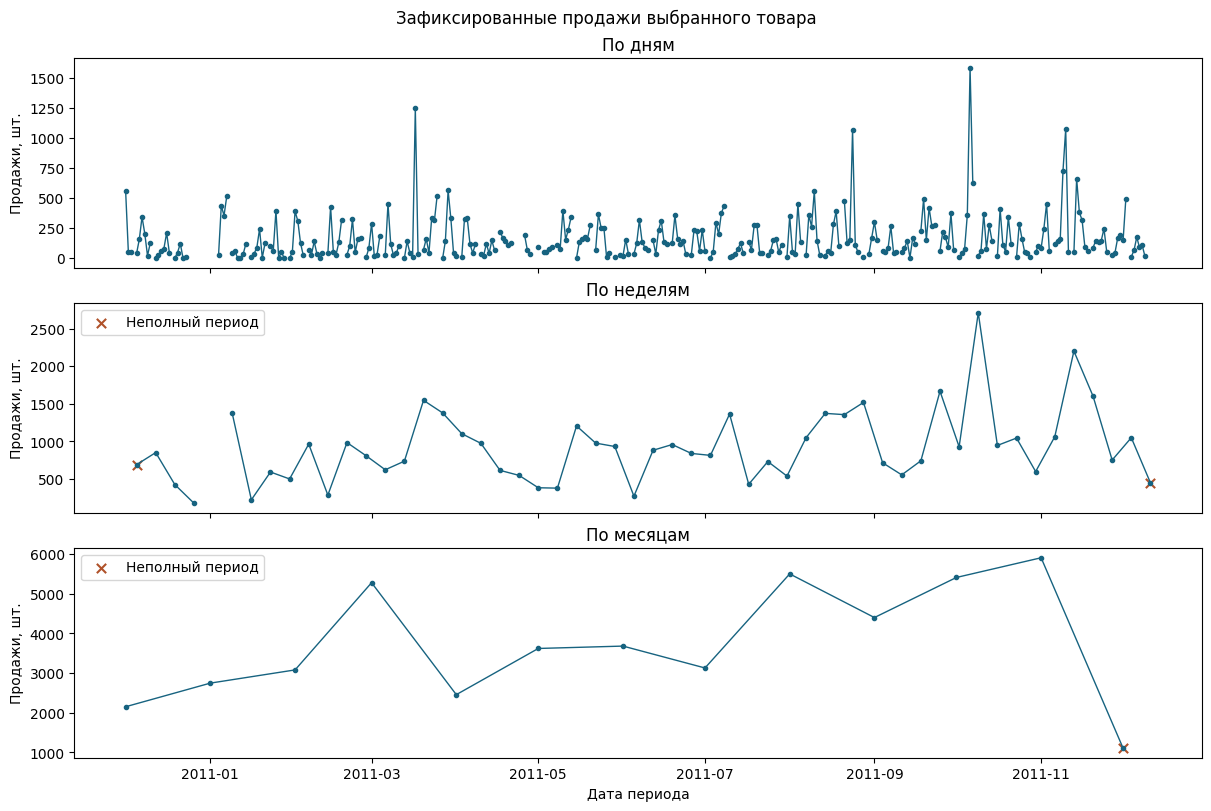

In [5]:
daily = build_calendar(retail, stock_code)
weekly = aggregate_calendar(daily, "W-SUN")
monthly = aggregate_calendar(daily, "MS")
full_weeks = weekly.loc[weekly["full_period"]]
week_sales = full_weeks[SALES]
sales_per_observed_day = week_sales / full_weeks["observed_days"]

plot_aggregations(daily, weekly, monthly)
export_series(daily, weekly, monthly)

## 2. Пропуски и выбросы

Если по магазину в этот день есть подтверждённые продажи, а по выбранному коду нет, записываю ноль зафиксированных продаж товара. Это не оценка спроса: неизвестно, был ли товар в наличии. Если продажи магазина не подтверждены, оставляю пропуск, даже при наличии служебных записей. Повторяемость разрывов по календарю проверяю отдельно.

Для диагностики всплесков использую полные календарные недели. В каждой точке сравниваю сумму продаж с локальной медианой соседей в окне из 13 недель. При ненулевом медианном абсолютном отклонении отмечаю точки, у которых отклонение больше 3,5 робастного стандартного отклонения. Сама точка из расчёта порога исключена.

In [6]:
calendar_audit = daily["status"].value_counts().rename("Дней")
unknown = daily.loc[daily[SALES].isna()].copy()
unknown["День недели"] = [WEEKDAYS[i] for i in unknown.index.dayofweek]
missing_profile = unknown["День недели"].value_counts().reindex(WEEKDAYS, fill_value=0)
display(calendar_audit.to_frame())
display(missing_profile.rename("Ненаблюдаемых дней").to_frame().T)
display(Markdown(
    "**Даты без подтверждённых продаж магазина, кроме суббот:** "
    + (", ".join(unknown.loc[unknown.index.dayofweek != 5].index.strftime("%d.%m.%Y")) or "нет")
    + ". Полный перечень дат и статусов сохранён в дневном ряду."
))

,Дней
status,
Есть продажи,300
Нет записей магазина,69
Нет продаж товара,5


День недели,Пн,Вт,Ср,Чт,Пт,Сб,Вс
Ненаблюдаемых дней,6,1,1,1,4,53,3


**Даты без подтверждённых продаж магазина, кроме суббот:** 24.12.2010, 26.12.2010, 27.12.2010, 28.12.2010, 29.12.2010, 30.12.2010, 31.12.2010, 02.01.2011, 03.01.2011, 22.04.2011, 24.04.2011, 25.04.2011, 29.04.2011, 02.05.2011, 30.05.2011, 29.08.2011. Полный перечень дат и статусов сохранён в дневном ряду.

,"Продажи, шт.",Локальная медиана,Робастная оценка,Наблюдаемых дней,"Самая крупная строка, шт."
date,,,,,
2011-11-13,2200.0,1045.0,6.72,6,1000


Недель без вычислимой робастной оценки: 2


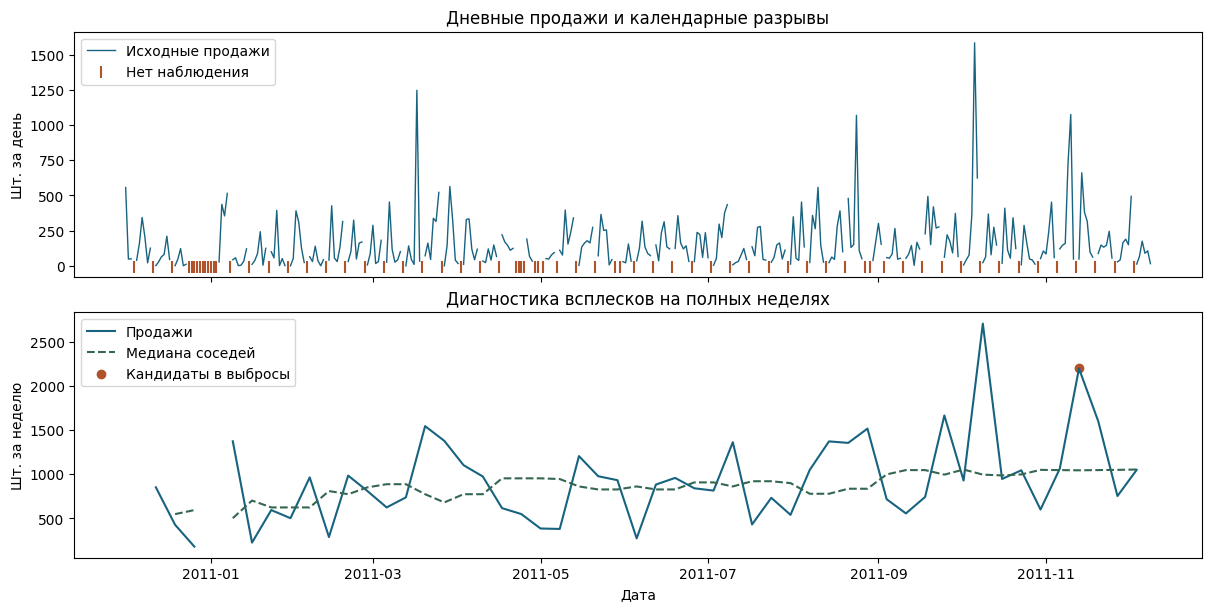

In [7]:
spikes = detect_spikes(week_sales)
flagged_weeks = spikes.loc[spikes["flag"]]
plot_quality(daily, spikes)
spike_summary = flagged_weeks.join(full_weeks["observed_days"]).copy()
spike_summary["Самая крупная строка, шт."] = [
    product_rows.loc[
        product_rows["is_sale"] & product_rows["day"].between(end - pd.Timedelta(days=6), end),
        "Quantity",
    ].max()
    for end in spike_summary.index
]
display(spike_summary.rename(columns={
    "value": "Продажи, шт.", "median": "Локальная медиана", "score": "Робастная оценка",
    "flag": "Есть всплеск", "observed_days": "Наблюдаемых дней",
}).drop(columns="Есть всплеск").round(2))
print(f"Недель без вычислимой робастной оценки: {spikes['score'].isna().sum()}")

Помеченные недели оставляю в ряду. Для каждого всплеска смотрю покрытие и размер крупнейшей строки заказа: закупка оптом и накопление нескольких заказов могут давать большие, но корректные объёмы. Без независимого подтверждения ошибки вырезание таких недель исказило бы прогнозируемую величину.

## 3. Описательные статистики и выбор частоты

Дневная агрегация сохраняет календарный ритм и всплески. Недельная сглаживает различия внутри недели и даёт больше наблюдений, чем месячная. Для диагностики уровня и стационарности использую полные календарные недели. Краевые недели и месяцы остаются на графике, но исключены из сравнительной статистики. Нормировка на число дней с зафиксированными продажами магазина служит проверкой чувствительности к разному покрытию.

,Дни,Полные недели,Полные месяцы
Периодов,374.00,52.00,12.00
Без наблюдения,69.00,1.00,0.00
"Доля нулей, %",1.64,0.00,0.00
Среднее,158.93,928.06,3947.42
Медиана,105.00,883.00,3651.00
Стандартное отклонение,189.08,488.02,1310.21
Коэффициент вариации,1.19,0.53,0.33
Минимум,0.00,180.00,2151.00
Максимум,1583.00,2709.00,5909.00
Асимметрия,3.24,1.26,0.23


,Недель,Среднее,Медиана,Ст. отклонение
date,,,,
2010Q4,3,486.33,427.0,339.91
2011Q1,13,835.83,774.0,429.19
2011Q2,13,775.46,883.0,300.82
2011Q3,13,989.46,815.0,418.01
2011Q4,10,1289.80,1047.5,676.64


,Недель
observed_days,
0,1
4,3
5,4
6,44


Коэффициент вариации равен 1.19 для дней, 0.53 для недель и 0.33 для месяцев. Для недель доступно 51 наблюдение из 52 полных календарных периодов, для полных месяцев — 12. Недельная частота даёт компромисс между шумом и длиной ряда.

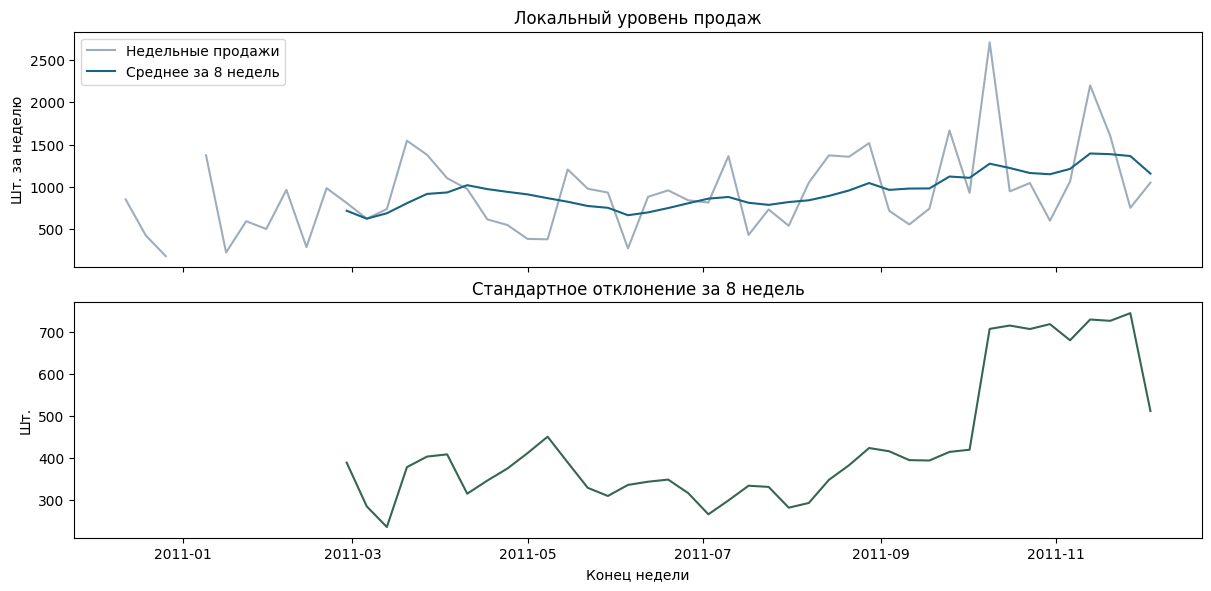

In [8]:
comparison = pd.DataFrame({
    "Дни": describe_series(daily[SALES]),
    "Полные недели": describe_series(week_sales),
    "Полные месяцы": describe_series(monthly.loc[monthly["full_period"], SALES]),
})
display(comparison.round(2))
display(quarter_profile(week_sales).round(2))
display(full_weeks["observed_days"].value_counts().sort_index().rename("Недель").to_frame())
plot_rolling(week_sales)

cv_day, cv_week, cv_month = comparison.loc["Коэффициент вариации"]
display(Markdown(
    f"Коэффициент вариации равен {cv_day:.2f} для дней, {cv_week:.2f} для недель "
    f"и {cv_month:.2f} для месяцев. Для недель доступно {week_sales.count()} наблюдение из {len(week_sales)} полных календарных периодов, "
    f"для полных месяцев — {monthly['full_period'].sum()}. "
    "Недельная частота даёт компромисс между шумом и длиной ряда."
))

Внутри 2011 года недельное среднее растёт с 775 шт. во втором квартале до 1 290 шт. в наблюдаемой части четвёртого. Недельный разброс за те же периоды вырос с 301 до 677 шт. Рост неровный: на графике заметны временные спады, а четвёртый квартал в выгрузке заканчивается в начале декабря.

## 4. Тренд и сезонность

Для поиска недельного ритма использую дневную устойчивую STL-декомпозицию с периодом 7: уровень продаж раскладывается на тренд, сезонную часть и остаток. Метод требует непрерывной календарной сетки. Поэтому только для STL в день недели, когда магазин ни разу не имел подтверждённых продаж, ставлю структурный ноль; остальные разрывы заполняю локальной медианой для того же дня недели. Это ретроспективная диагностика: центрированные окна используют будущие наблюдения, поэтому такой ряд не переносится в прогноз. Исходные дневные суммы и результаты диагностики сохраняются отдельно.

Сам факт выделения STL-компоненты при периоде 7 ещё не доказывает сезонность. Смотрю силу компоненты по отношению дисперсий, корреляцию на лаге 7 и профиль по дням недели. Дополнительно сравниваю дни в пределах полных наблюдаемых недель критерием Фридмана на значениях после удаления тренда. В этот критерий не входят заполненные дни. При зависимости соседних недель его результат служит диагностикой, а не строгим доказательством.

**Заполнение только для STL:** структурных нулей — 53, оценённых дней — 16. Сила недельной компоненты — 0.22; корреляция на лаге 7 после удаления тренда на наблюдаемых парах — 0.11. Для критерия Фридмана использовано 44 недель, p = 6.21e-07, согласованность рангов Кендалла W = 0.17.

,Дней,Среднее,Медиана
День недели,,,
Пн,47,164.62,105.0
Вт,52,178.40,150.5
Ср,53,191.38,135.0
Чт,53,219.11,134.0
Пт,50,137.36,83.0
Вс,50,56.72,30.0


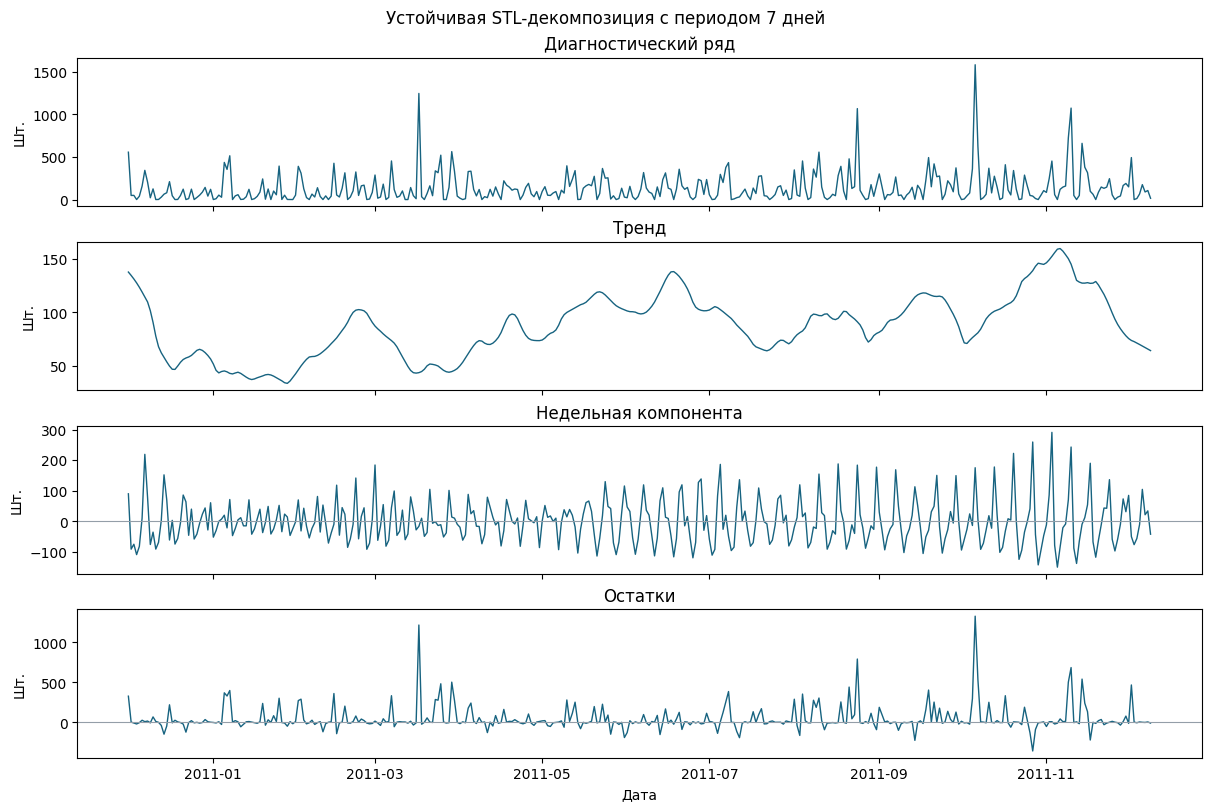

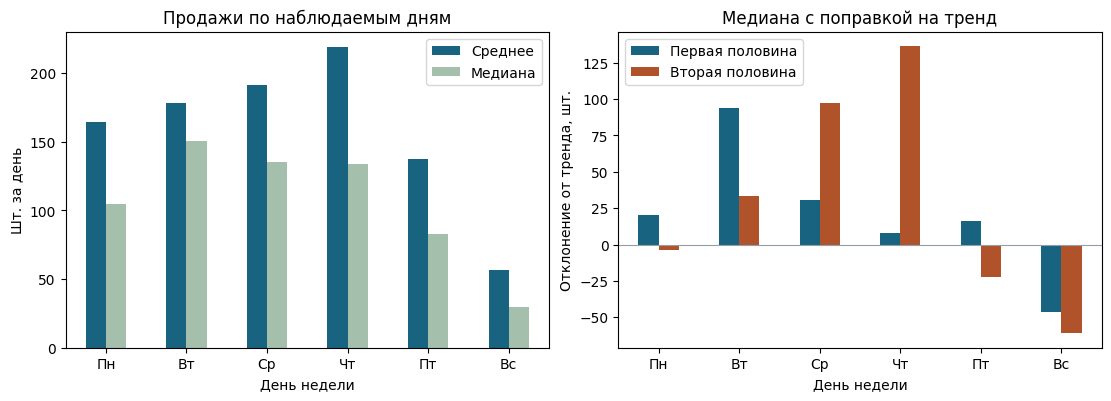

In [9]:
components, strength = decompose_daily(daily)
profile, halves, weekday_p, weekday_w, matched_weeks, lag7 = weekday_diagnostics(daily, components)

display(Markdown(
    f"**Заполнение только для STL:** структурных нулей — {components['structural'].sum()}, "
    f"оценённых дней — {components['estimated'].sum()}. "
    f"Сила недельной компоненты — {strength:.2f}; корреляция на лаге 7 "
    f"после удаления тренда на наблюдаемых парах — {lag7:.2f}. "
    f"Для критерия Фридмана использовано {matched_weeks} недель, "
    f"p = {weekday_p:.3g}, согласованность рангов Кендалла W = {weekday_w:.2f}."
))
display(profile.rename(columns={"size": "Дней", "mean": "Среднее", "median": "Медиана"}).round(2))
plot_decomposition(components)
plot_weekdays(profile, halves)

In [10]:
first_level = components["trend"].iloc[:28].median()
last_level = components["trend"].iloc[-28:].median()
residual_q95 = components["residual"].abs().quantile(0.95)
display(Markdown(
    f"**Тренд.** Медиана тренда за первые и последние 28 дней: "
    f"{first_level:.1f} и {last_level:.1f} шт. за день. "
    f"**Остатки.** 95% абсолютных остатков не превышают {residual_q95:.1f} шт."
))

**Тренд.** Медиана тренда за первые и последние 28 дней: 64.6 и 96.6 шт. за день. **Остатки.** 95% абсолютных остатков не превышают 334.3 шт.

**Сезонность.** У ряда есть недельный календарный ритм, особенно устойчиво низкие воскресные продажи: медиана составляет 30 шт., отклонение от тренда отрицательно в обеих половинах выборки. При этом связь соседних недель слабая (лаг 7: 0,11), и типичный наиболее активный день меняется. Поэтому недельный профиль полезен как календарный признак, но сезонная компонента не объясняет большую часть вариации. Субботний ноль в STL — допущение для расчёта, а не отдельное подтверждение сезона. Для оценки годовой повторяемости недостаточно циклов.

## 5. Стационарность и разности

ADF проверяет нулевую гипотезу о единичном корне, KPSS — о стационарности вокруг константы. Уровень значимости — 5%. Согласованный результат в пользу стационарности: ADF отклоняет свою нулевую гипотезу, KPSS свою не отклоняет. Если выводы расходятся, нельзя подтвердить стационарность только по одному тесту. Граница p в таблице означает, что число выходит за диапазон табличного приближения KPSS.

Тесты требуют регулярного ряда. Беру самый длинный непрерывный участок полных календарных недель и не склеиваю значения через разрыв. В остальных разделах использую всю историю. Чтобы отделить смену уровня от разницы в количестве наблюдаемых дней, дополнительно проверяю средние продажи на наблюдаемый день недели. Первые разности считаю как изменение объёма относительно предыдущей недели; первая точка теряется. Сравнение с ними помогает выбрать преобразование, если оно потребуется. Порядок дифференцирования при будущем прогнозировании нужно проверять на обучающей части ряда.

Непрерывный участок: 09.01.2011 — 04.12.2011; 48 недель


Недельные суммы: Оба теста отклоняют H₀; простой вывод о стационарности невозможен.
Продажи на наблюдаемый день: Тесты согласуются с нестационарностью уровня.
Первые разности сумм: Тесты согласуются со стационарностью вокруг константы.


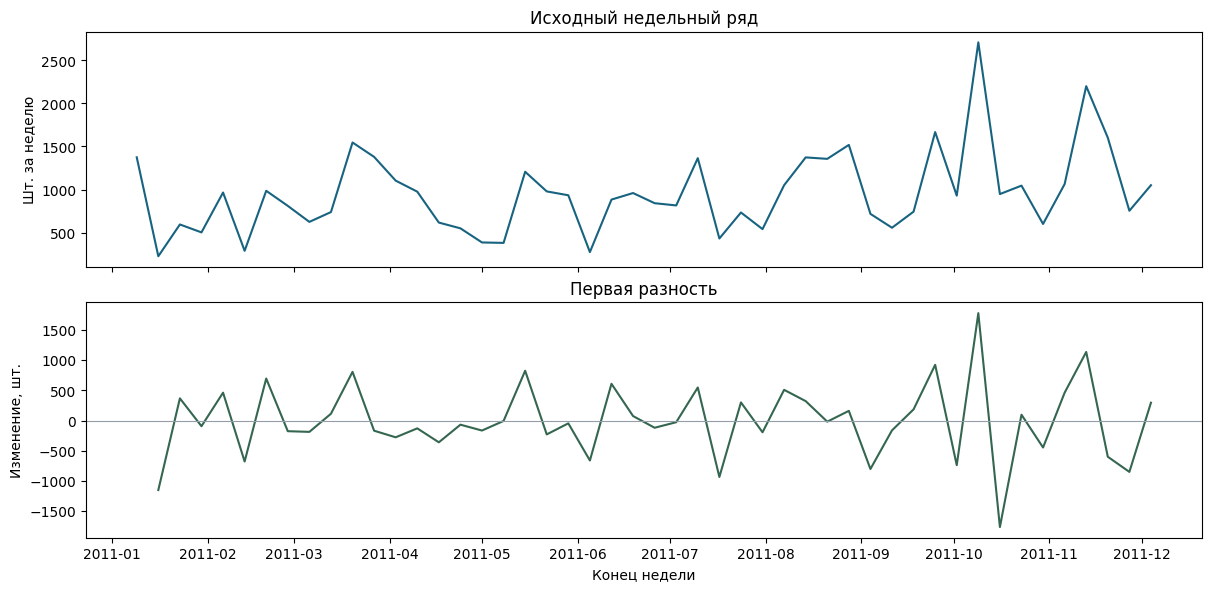

In [11]:
regular_weeks = longest_observed_run(week_sales)
regular_rate = sales_per_observed_day.loc[regular_weeks.index]
changes = regular_weeks.diff().iloc[1:]
print(f"Непрерывный участок: {regular_weeks.index[0]:%d.%m.%Y} — "
      f"{regular_weeks.index[-1]:%d.%m.%Y}; {len(regular_weeks)} недель")
checks = {
    "Недельные суммы": stationarity_tests(regular_weeks, ALPHA),
    "Продажи на наблюдаемый день": stationarity_tests(regular_rate, ALPHA),
    "Первые разности сумм": stationarity_tests(changes, ALPHA),
}
test_table = pd.concat(checks, names=["Ряд"])
display(test_table.style.format({"Статистика": "{:.4f}", "p": "{:.4g}"}))
for label, table in checks.items():
    print(f"{label}: {stationarity_status(table)}")

plot_difference(regular_weeks, changes)

## 6. Выводы

- Всего зафиксировано **48 474 шт.** товара `85099B`. Из 374 календарных дней 300 содержат продажи товара, ещё 5 — наблюдаемые нули, а в 69 нет записей магазина. Полностью ненаблюдаемая неделя заканчивается 2 января 2011 года. Её оставляю пропуском.
- Единственный всплеск, отмеченный локальным критерием, — **2 200 шт. за неделю до 13 ноября**. Одна строка содержит 1 000 шт. Это объясняет существенную долю объёма; наблюдение сохраняю.
- Для дальнейшего анализа разумна **недельная частота**: она даёт 51 наблюдаемую полную неделю против 12 полных месяцев и меньше относительного шума, чем дневная. Продажи растут к концу периода, разброс увеличивается. На дневной частоте виден недельный календарный ритм, но слабо выражена повторяемость объёмов от недели к неделе.
- Для недельных сумм ADF отклоняет единичный корень (p ≈ 8,15 × 10⁻⁷), но KPSS также отклоняет стационарность уровня (p ≈ 0,0356). Нормировка на наблюдаемые дни не устраняет расхождение с гипотезой о стационарном уровне: KPSS p ≈ 0,0431.
- Для первых разностей обе проверки согласуются со стационарностью вокруг константы (ADF p ≈ 0,0153, KPSS p ≥ 0,10). Это аргумент попробовать разности в моделях, которым нужен стационарный вход. Он не доказывает единичный корень в исходном ряду и не исключает детерминированный тренд. При прогнозировании стоит сравнить оба подхода по отложенным по времени данным.

Отфильтрованные исходные суммы не подменены разностями или значениями для STL. Без данных об остатках товара этот ряд позволяет изучать зарегистрированные продажи, а не скрытый спрос.